In [2]:
from helpers import *

parameters defined, as expanded / ugly as possible

In [3]:
embedding_size = 3
nhidden = 200
nin = embedding_size*context_size

EMB = torch.randn(27, embedding_size)

W1 = torch.randn((nin,nhidden)) * (5/3) / nin**0.5
b1 = torch.randn(nhidden) * 0.1

W2 = torch.randn((nhidden,27)) * 0.1
b2 = torch.randn(27) * 0.1

bngain = torch.randn((1, nhidden))*0.1 + 1.0
bnbias = torch.randn((1, nhidden))*0.1

params = [EMB, W1, b1, W2, b2, bngain, bnbias]

for p in params:
	p.requires_grad = True

forward pass

In [32]:
n = 32
ixs = torch.randint(0, Xtrain.shape[0], (n,))

ctx, target = Xtrain[ixs], Ytrain[ixs]
emb = EMB[ctx]
embcat = emb.view(-1, nin)

# Linear 1
h_pre_bn = embcat @ W1 + b1

# BatchNorm 1
bn_mean_i = h_pre_bn.sum(0, keepdim=True) / n
bn_diff = h_pre_bn - bn_mean_i
bn_diff2 = bn_diff**2
bn_var = bn_diff2.sum(0, keepdim=True) / (n-1)
bn_var_inv = (bn_var + 1e-5)**-0.5
bn_raw = bn_diff * bn_var_inv
h_pre_act = bngain * bn_raw + bnbias

# Tanh
h = torch.tanh(h_pre_act)

# Linear 2
logits = h @ W2 + b2

# Cross Entropy
logits_max = logits.max(1, keepdim=True).values
norm_logits = logits - logits_max
counts = norm_logits.exp()
counts_sum = counts.sum(1, keepdim=True)
counts_sum_inv = counts_sum**-1
probs = counts * counts_sum_inv
logprobs = probs.log()
loss = -logprobs[range(n), target].mean()
loss.item()

3.750758409500122

backwards pass, line by line

In [54]:
# Cross Entropy
dloss = torch.ones_like(loss)
dlogprobs = torch.zeros_like(logprobs)
dlogprobs[range(n), target] = - 1/n 		# loss = - 1/n * sum(logprobs)
dprobs = dlogprobs * (1 / probs)			# logprobs = ln(probs)
dcounts_sum_inv = (dprobs * counts).sum(1, keepdims=True) # probs = counts * counts_sum_inv
dcounts_sum = dcounts_sum_inv * (-counts_sum**-2) # counts_sum_inv = counts_sum**-1

dcounts = dcounts_sum * torch.ones_like(counts)	  # counts_sum = sum(counts)
dcounts += dprobs * counts_sum_inv				  # probs = counts * counts_sum_inv
dnorm_logits = dcounts * counts					  # counts = exp(norm_logits)
dlogits_max = (-dnorm_logits).sum(1, keepdims=True) # norm_logits = logits - logits_max

# Linear 2
dlogits = dnorm_logits.clone() 	# norm_logits = logits - logits_max
dlogits += dlogits_max * F.one_hot(logits.max(1).indices, num_classes=logits.shape[1]) # logits_max = max(logits)

# Tanh
dh = dlogits @ W2.T # logits = h @ W2 + b2
dW2 = h.T @ dlogits
db2 = dlogits.sum(0)

# BatchNorm
dh_pre_act = dh * (1.0 - h**2) 	# h = tanh(h_pre_act)
dbngain = (dh_pre_act * bn_raw).sum(0, keepdim=True)	# h_pre_act = bngain * bn_raw + bnbias
dbnbias = dh_pre_act.sum(0, keepdim=True)
dbn_raw = dh_pre_act * bngain

dbn_var_inv = (dbn_raw * bn_diff).sum(0, keepdims=True)
dbn_var = dbn_var_inv * -0.5 * (bn_var + 1e-5)**-1.5
dbn_diff2 = dbn_var * torch.ones_like(bn_diff2) / (n-1)
dbn_diff = dbn_diff2 * 2 * bn_diff
dbn_diff += dbn_raw * bn_var_inv
dbn_mean_i = (-dbn_diff).sum(0)

# Linear 
dh_pre_bn = dbn_mean_i * torch.ones_like(h_pre_bn) / n
dh_pre_bn += dbn_diff.clone()

dembcat = dh_pre_bn @ W1.T
dW1 = embcat.T @ dh_pre_bn
db1 = dh_pre_bn.sum(0)

demb = dembcat.view(emb.shape)


pytorch backwards pass

In [34]:
# PyTorch backward pass
for p in params:
  p.grad = None
for t in [logprobs, probs, counts, counts_sum, counts_sum_inv,
          norm_logits, logits_max, logits, h, h_pre_act, bn_raw,
         bn_var_inv, bn_var, bn_diff2, bn_diff, h_pre_bn, bn_mean_i,
         embcat, emb]:
  t.retain_grad()
loss.backward()
loss.item()

3.750758409500122

In [28]:
# utility function we will use later when comparing manual gradients to PyTorch gradients
def cmp(s, dt, t):
  ex = torch.all(dt == t.grad).item()
  app = torch.allclose(dt, t.grad)
  maxdiff = (dt - t.grad).abs().max().item()
  print(f'{s:15s} | exact: {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}')

In [55]:
cmp('logprobs', dlogprobs, logprobs)
cmp('probs', dprobs, probs)
cmp('counts_sum_inv', dcounts_sum_inv, counts_sum_inv)
cmp('counts_sum', dcounts_sum, counts_sum)
cmp('counts', dcounts, counts)
cmp('norm_logits', dnorm_logits, norm_logits)
cmp('logits_max', dlogits_max, logits_max)
cmp('logits', dlogits, logits)
cmp('h', dh, h)
cmp('W2', dW2, W2)
cmp('b2', db2, b2)
cmp('h_pre_act', dh_pre_act, h_pre_act)
cmp('bngain', dbngain, bngain)
cmp('bnbias', dbnbias, bnbias)
cmp('bn_raw', dbn_raw, bn_raw)
cmp('bn_var_inv', dbn_var_inv, bn_var_inv)
cmp('bn_var', dbn_var, bn_var)
cmp('bn_diff2', dbn_diff2, bn_diff2)
cmp('bn_diff', dbn_diff, bn_diff)
cmp('bn_mean_i', dbn_mean_i, bn_mean_i)
cmp('h_pre_bn', dh_pre_bn, h_pre_bn)
cmp('embcat', dembcat, embcat)
cmp('W1', dW1, W1)
cmp('b1', db1, b1)
cmp('emb', demb, emb)

logprobs        | exact: True  | approximate: True  | maxdiff: 0.0
probs           | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum      | exact: True  | approximate: True  | maxdiff: 0.0
counts          | exact: True  | approximate: True  | maxdiff: 0.0
norm_logits     | exact: True  | approximate: True  | maxdiff: 0.0
logits_max      | exact: True  | approximate: True  | maxdiff: 0.0
logits          | exact: True  | approximate: True  | maxdiff: 0.0
h               | exact: True  | approximate: True  | maxdiff: 0.0
W2              | exact: True  | approximate: True  | maxdiff: 0.0
b2              | exact: True  | approximate: True  | maxdiff: 0.0
h_pre_act       | exact: False | approximate: True  | maxdiff: 4.656612873077393e-10
bngain          | exact: False | approximate: True  | maxdiff: 2.3283064365386963e-09
bnbias          | exact: False | approximate: True  | maxdiff: 3.725290298461914e-09
bn_raw 

condensing CrossEntropyLoss

In [57]:
# before:
# logit_maxes = logits.max(1, keepdim=True).values
# norm_logits = logits - logit_maxes # subtract max for numerical stability
# counts = norm_logits.exp()
# counts_sum = counts.sum(1, keepdims=True)
# counts_sum_inv = counts_sum**-1 # if I use (1.0 / counts_sum) instead then I can't get backprop to be bit exact...
# probs = counts * counts_sum_inv
# logprobs = probs.log()
# loss = -logprobs[range(n), Yb].mean()

dlogits = F.softmax(logits, 1)
dlogits[range(n), target] -= 1
dlogits /= n

cmp('logits', dlogits, logits)

logits          | exact: False | approximate: True  | maxdiff: 8.847564458847046e-09


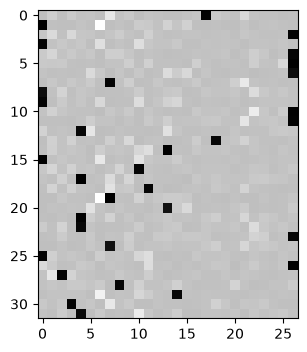

In [58]:
plt.figure(figsize=(4, 4))
plt.imshow(dlogits.detach(), cmap='gray')

batchnorm condensed

In [61]:
# before:
# bnmeani = 1/n*hprebn.sum(0, keepdim=True)
# bndiff = hprebn - bnmeani
# bndiff2 = bndiff**2
# bnvar = 1/(n-1)*(bndiff2).sum(0, keepdim=True) # note: Bessel's correction (dividing by n-1, not n)
# bnvar_inv = (bnvar + 1e-5)**-0.5
# bnraw = bndiff * bnvar_inv
# hpreact = bngain * bnraw + bnbias

hpreact_fast = (bngain * (h_pre_bn - h_pre_bn.mean(0, keepdim=True))
			/ torch.sqrt(h_pre_bn.var(0, keepdim=True, unbiased=True) + 1e-5)
			+ bnbias)
print('max diff:', (hpreact_fast - h_pre_act).abs().max())

max diff: tensor(4.7684e-07, grad_fn=<MaxBackward1>)


In [ ]:
# before we had:
# dbnraw = bngain * dhpreact
# dbndiff = bnvar_inv * dbnraw
# dbnvar_inv = (bndiff * dbnraw).sum(0, keepdim=True)
# dbnvar = (-0.5*(bnvar + 1e-5)**-1.5) * dbnvar_inv
# dbndiff2 = (1.0/(n-1))*torch.ones_like(bndiff2) * dbnvar
# dbndiff += (2*bndiff) * dbndiff2
# dhprebn = dbndiff.clone()
# dbnmeani = (-dbndiff).sum(0)
# dhprebn += 1.0/n * (torch.ones_like(hprebn) * dbnmeani)

dhprebn = (
	bngain*bn_var_inv/n * 
	(n * dh_pre_act - dh_pre_act.sum(0) - n/(n-1)*bn_raw*(dh_pre_act*bn_raw).sum(0))
)

cmp('hprebn', dhprebn, h_pre_bn)

hprebn          | exact: False | approximate: True  | maxdiff: 9.313225746154785e-10
